In [123]:
import dispatch
import dispatch.select as ds
import dispatch.yt as dyt
import numpy as np
import yt as yt
import matplotlib.pyplot as pl

In [124]:
import dispatch.graphics as dg
def im3(pp,iv,vmin,vmax,varname): #,ylim0=0,ylim1=3):
    #pl.xlim(0,1)#; pl.ylim(ylim0,ylim1)
    num_patches = len(pp.patches)
    n=pp.patches[0].n
    n[2]=1
    g=pp.patches[0].ng
    m=int(n[1]/2 -1)
    pos_arr = np.zeros([int(pp.cartesian.dims[0]),int(pp.cartesian.dims[1]),int(pp.cartesian.dims[2])])
    patch_arr = np.zeros([np.shape(pos_arr)[0]*n[0], np.shape(pos_arr)[1]*n[1], np.shape(pos_arr)[2]*n[2]])
    for ip in range(num_patches):
        p = pp.patches[ip]
        position = [int((p.position[0]-pp.cartesian.origin[0])*pp.cartesian.dims[0]), int((p.position[1]-pp.cartesian.origin[1])*pp.cartesian.dims[1]), int(p.position[2])]
        #position=[0,0,0]
        #print (pp.cartesian.dims)
        #print (ip,position,p.position)
        pos_arr[position[0], position[1], position[2]] = p.id
        if (iv==10):
            data= (p.var(5)**2+p.var(6)**2)/(8*np.pi)
            varname='magnetic pressure'
        elif (iv==11):
            data= (p.var(4)*(s.gamma-1.0))
            varname='gas pressure'
        else:
            data=p.data[iv] if hasattr(p,'data') else p.var(iv)
        no_gz=data[g[0]:-g[0],g[1]:-g[1],:]
        no_gz=data
        #no_gz=data[g[0]:-g[0],g[1]:-g[1],g[2]:-g[2]]
        patch_arr[position[0]*n[0]:position[0]*n[0]+n[0],position[1]*n[1]:position[1]*n[1]+n[1],position[2]*n[2]:position[2]*n[2]+n[2]] = no_gz
    #print(pos_arr)
    #print(np.shape(patch_arr.transpose()))
    #final = np.sum(patch_arr,axis=1).transpose() #.transpose().reshape(n[0]*3,n[0]*3)
    final = patch_arr[:,:,0].transpose()
    pl.imshow(final, cmap='viridis')
    pl.title(varname); 
    pl.colorbar(shrink=0.1)
def getvar(pp,iv): #,ylim0=0,ylim1=3):
    #pl.xlim(0,1)#; pl.ylim(ylim0,ylim1)
    num_patches = len(pp.patches)
    n=pp.patches[0].n
    n[2]=1
    g=pp.patches[0].ng
    m=int(n[1]/2 -1)
    pos_arr = np.zeros([int(pp.cartesian.dims[0]),int(pp.cartesian.dims[1]),int(pp.cartesian.dims[2])])
    patch_arr = np.zeros([np.shape(pos_arr)[0]*n[0], np.shape(pos_arr)[1]*n[1], np.shape(pos_arr)[2]*n[2]])
    for ip in range(num_patches):
        p = pp.patches[ip]
        position = [int((p.position[0]-pp.cartesian.origin[0])*pp.cartesian.dims[0]), int((p.position[1]-pp.cartesian.origin[1])*pp.cartesian.dims[1]), int(p.position[2])]
        #position=[0,0,0]
        #print (ip,position,p.position)
        pos_arr[position[0], position[1], position[2]] = p.id
        if (iv==10):
            data= (p.var(5)**2+p.var(6)**2)/(8*np.pi)
            varname='magnetic pressure'
        elif (iv==11):
            data= (p.var(4)*(s.gamma-1.0))
            varname='gas pressure'
        else:
            data=p.data[iv] if hasattr(p,'data') else p.var(iv)
        #no_gz=data[g[0]:-g[0],g[1]:-g[1],:]
        no_gz=data
        #no_gz=data[g[0]:-g[0],g[1]:-g[1],g[2]:-g[2]]
        patch_arr[position[0]*n[0]:position[0]*n[0]+n[0],position[1]*n[1]:position[1]*n[1]+n[1],position[2]*n[2]:position[2]*n[2]+n[2]] = no_gz
    #print(pos_arr)
    #print(np.shape(patch_arr.transpose()))
    #final = np.sum(patch_arr,axis=1).transpose() #.transpose().reshape(n[0]*3,n[0]*3)
    final = patch_arr[:,:,0].transpose()
    return final

In [125]:
s.patches[0].position

array([-0.42857143, -0.42857143,  0.0005    ])

In [126]:
data='../data'
#run = 'stagger2'
run = ''
#run = 'ramses'
#dg.image_plane(snap=s,x=None,y=None,z=0.0,iv=7,verbose=False)

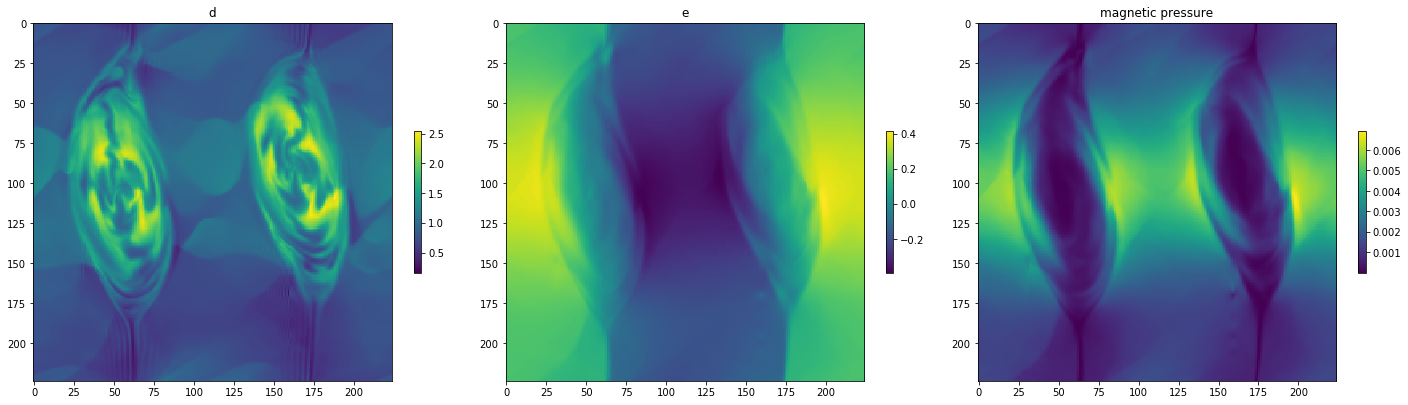

In [133]:
iout=330
s=dispatch.snapshot(iout=iout,run=run,data=data, copy=True,verbose=0)
pl.figure(1, figsize=(20,20))
pl.clf()
        #print "e, max,min,mean", np.max(pp[1].data[:,:,:,0]), np.min(pp[1].data[:,:,:,0]), np.mean(pp[1].data[:,:,:,0])
        #for ip in range(num_patches):
        #    pp = ss[it].patches[ip]
        #    #density = pp.data[0]
pl.subplot(1,3,1); im3(s, 0, 470, 530 ,'d')#,ylim0,ylim1)
pl.subplot(1,3,2); im3(s, 6, -.20, +.20 ,'e' )
        #pl.subplot(1,4,2); im3(ss[it], 7, 0.00, 0.08, 'bz')#,ylim0,ylim1)
pl.subplot(1,3,3); im3(s, 10, -.20, +.20, 'bx')#,ylim0,ylim1)
#pl.subplot(2,2,4); im3(s, 11, -.20, +.20, 'by')#,ylim0,ylim1)
pl.tight_layout()
pl.draw()
pl.pause(0.001)
pl.show()

(224, 224) (224, 224)


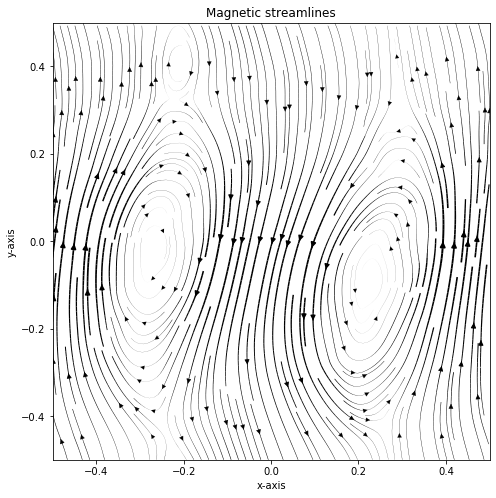

In [106]:
bx=getvar(s,5)
by=getvar(s,6)
bs=getvar(s,10)
import matplotlib.gridspec as gridspec
fig = pl.figure(figsize=(7, 9))
gs = gridspec.GridSpec(nrows=1, ncols=1, height_ratios=[1])
ax = fig.add_subplot(gs[0,0])
N=bx.shape[0]
print (bx.shape, bs.shape)
x = y = np.linspace(-0.5,0.5,N,endpoint=True)
yv,xv = np.mgrid[-0.5:0.5:224j, -0.5:0.5:224j]
ax.set_title('Magnetic streamlines')
ax.set_xlabel('x-axis')
ax.set_ylabel('y-axis')
ax.streamplot(
   xv,
   yv,
   bx,
   by,
   density=[2.0,3.0],
   color='black',
   linewidth=(bs/bs.max()) * 2.0)

ax.set_xlim([-0.5,0.5])
ax.set_ylim([-0.5,0.5])
ax.set_aspect('equal')
ax.grid(False)
        #print "e, max,min,mean", np.max(pp[1].data[:,:,:,0]), np.min(pp[1].data[:,:,:,0]), np.mean(pp[1].data[:,:,:,0])
        #for ip in range(num_patches):
        #    pp = ss[it].patches[ip]
        #    #density = pp.data[0]
pl.tight_layout()
pl.show()

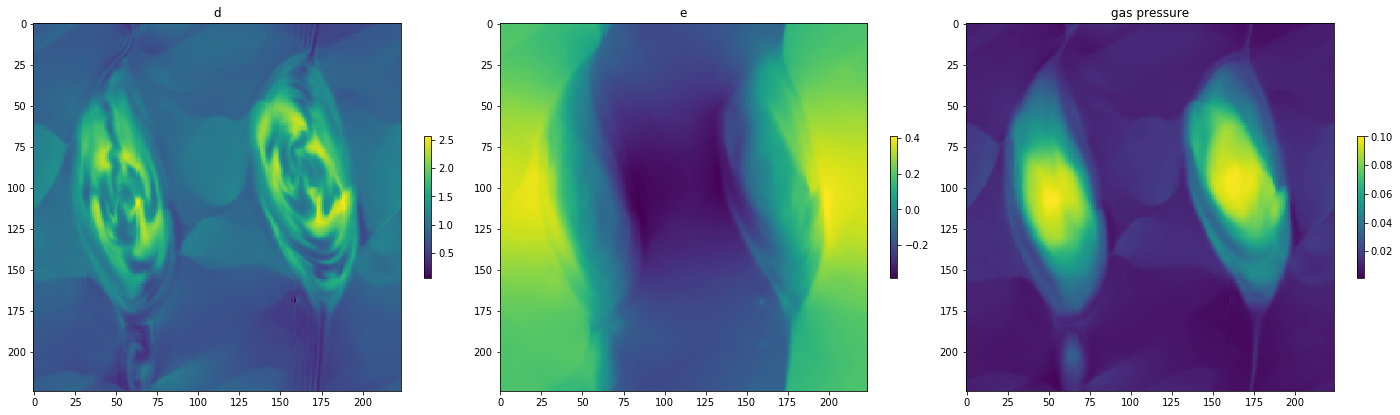

In [107]:
pl.figure(1, figsize=(20,20))
for iout in range(0,333):
    #iout=998
    s=dispatch.snapshot(iout=iout,run=run,data=data, copy=True,verbose=0)
    pl.clf()
            #print "e, max,min,mean", np.max(pp[1].data[:,:,:,0]), np.min(pp[1].data[:,:,:,0]), np.mean(pp[1].data[:,:,:,0])
            #for ip in range(num_patches):
            #    pp = ss[it].patches[ip]
            #    #density = pp.data[0]
    pl.subplot(1,3,1); im3(s, 0, 470, 530 ,'d')#,ylim0,ylim1)
    pl.subplot(1,3,2); im3(s, 6, -.20, +.20 ,'e' )
            #pl.subplot(1,4,2); im3(ss[it], 7, 0.00, 0.08, 'bz')#,ylim0,ylim1)
    pl.subplot(1,3,3); im3(s, 11, -.20, +.20, 'bx')#,ylim0,ylim1)
    #pl.subplot(2,2,4); im3(s, 11, -.20, +.20, 'by')#,ylim0,ylim1)
    pl.tight_layout()
    pl.draw()
    #pl.pause(0.01)
    #pl.show()
    pl.savefig("{}/{:03d}".format('figs',iout))

working on  0
working on  1
working on  2
working on  3
working on  4
working on  5
working on  6
working on  7
working on  8
working on  9
working on  10
working on  11
working on  12
working on  13
working on  14
working on  15
working on  16
working on  17
working on  18
working on  19


/mn/stornext/u3/andriusp/anaconda3/lib/python3.6/site-packages/ipykernel_launcher.py:9: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  if __name__ == '__main__':


working on  20
working on  21
working on  22
working on  23
working on  24
working on  25
working on  26
working on  27
working on  28
working on  29
working on  30
working on  31
working on  32
working on  33
working on  34
working on  35
working on  36
working on  37
working on  38
working on  39
working on  40
working on  41
working on  42
working on  43
working on  44
working on  45
working on  46
working on  47
working on  48
working on  49
working on  50
working on  51
working on  52
working on  53
working on  54
working on  55
working on  56
working on  57
working on  58
working on  59
working on  60
working on  61
working on  62
working on  63
working on  64
working on  65
working on  66
working on  67
working on  68
working on  69
working on  70
working on  71
working on  72
working on  73
working on  74
working on  75
working on  76
working on  77
working on  78
working on  79
working on  80
working on  81
working on  82
working on  83
working on  84
working on  85
working on

<Figure size 432x288 with 0 Axes>

<Figure size 504x648 with 0 Axes>

<Figure size 504x648 with 0 Axes>

... (325 outputs left out)

<Figure size 504x648 with 0 Axes>

<Figure size 504x648 with 0 Axes>

<Figure size 504x648 with 0 Axes>

<Figure size 504x648 with 0 Axes>

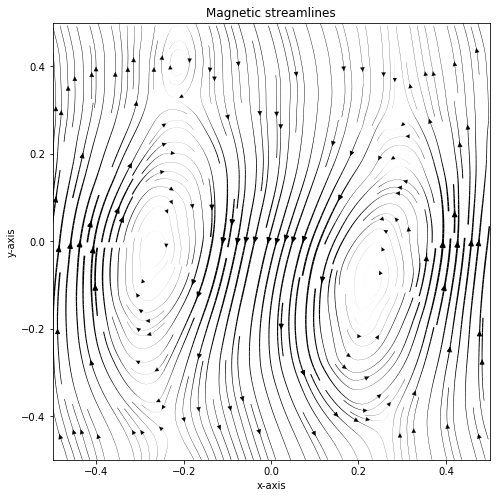

In [110]:
import matplotlib.gridspec as gridspec
for iout in range(0,332):
    print ('working on ', iout)
    s=dispatch.snapshot(iout=iout,run=run,data=data, copy=True,verbose=0)
    bx=getvar(s,5)
    by=getvar(s,6)
    bs=getvar(s,10)
    pl.clf()
    fig = pl.figure(figsize=(7, 9))
    gs = gridspec.GridSpec(nrows=1, ncols=1, height_ratios=[1])
    ax = fig.add_subplot(gs[0,0])
    N=bx.shape[0]
    x = y = np.linspace(-0.5,0.5,N,endpoint=True)
    yv,xv = np.mgrid[-0.5:0.5:224j, -0.5:0.5:224j]
    ax.set_title('Magnetic streamlines')
    ax.set_xlabel('x-axis')
    ax.set_ylabel('y-axis')
    ax.streamplot(
       xv,
       yv,
       bx,
       by,
       density=[2.0,3.0],
       color='black',
       linewidth=(bs/bs.max()) * 2.0)

    ax.set_xlim([-0.5,0.5])
    ax.set_ylim([-0.5,0.5])
    ax.set_aspect('equal')
    ax.grid(False)
            #print "e, max,min,mean", np.max(pp[1].data[:,:,:,0]), np.min(pp[1].data[:,:,:,0]), np.mean(pp[1].data[:,:,:,0])
            #for ip in range(num_patches):
            #    pp = ss[it].patches[ip]
            #    #density = pp.data[0]
    pl.tight_layout()
    pl.savefig("{}/{:03d}".format('contour',iout))